# JS06 - ANN (Approximate Nearest Neighbors)
**Muhammad Pearl Ocshada — 244107020064 — JTI Polinema — Pembelajaran Mesin 2025/2026**

**Ide dasar.** Mencari tetangga terdekat secara *exact* (KNN klasik) berarti menghitung jarak ke **seluruh** basis data — mahal saat data mencapai jutaan–miliaran vektor atau dimensi tinggi. **ANN (Approximate Nearest Neighbors)** menukar sedikit akurasi dengan kecepatan besar, dan menjadi fondasi optimasi pipeline KMeans & KNN pada Big Data.

**Metrik jarak yang umum:** Euclidean/L2, Inner Product, Cosine Similarity ∈ [−1,1], Angular Distance = cosine yang dipetakan ke [0,1] (0 = searah, 1 = berlawanan).

| Teknik | Library | Cara kerja |
|---|---|---|
| Random Projection Trees | Annoy (Spotify) | Banyak binary tree hasil potongan ruang oleh hyperplane acak; query hanya dicek pada leaf yang sama |
| Quantization + Clustering | FAISS (Meta) | IVF: ruang di-cluster k-means, query hanya membuka beberapa cluster; PQ: vektor dikompres ke codebook |
| Hierarchical Graph | HNSW | Graf bertingkat (level atas jarang → bawah rapat), greedy search dari atas ke bawah |

---
## Persiapan dataset benchmark (dipakai bersama untuk praktikum & tugas)

Dataset sintetis 10.000 vektor 128-dimensi (`seed=42`), distandardisasi, lalu dicari 10 tetangga terdekat untuk 1.000 query. Hasil *exact* dipakai sebagai ground truth untuk mengukur **recall@k** dan **waktu** tiap metode.

In [1]:
import time
import numpy as np
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
np.random.seed(42)

n_samples, dim, k = 10_000, 128, 10
X = np.random.rand(n_samples, dim).astype('float32')
X = StandardScaler().fit_transform(X).astype('float32')
X_query = X[:1000]
print('X:', X.shape, X.dtype)

X: (10000, 128) float32


### Baseline — Exact NN (brute force, ground truth)

In [2]:
from sklearn.neighbors import NearestNeighbors

t0 = time.time()
nn = NearestNeighbors(algorithm='brute', metric='euclidean').fit(X)
exact_dist, exact_idx = nn.kneighbors(X_query, n_neighbors=k)
t_exact = time.time() - t0
print(f'Exact brute force : {t_exact:.4f} s (search 1000 query, tanpa waktu fit)')

Exact brute force : 1.5036 s (search 1000 query, tanpa waktu fit)


---
## Praktikum 1–2 — ANNOY (Random Projection Trees)

Annoy membangun banyak binary tree; tiap split memakai **arah hyperplane acak**, dan berhenti saat leaf berisi sedikit item. Query menelusuri *setiap* pohon, menggabungkan kandidat dari leaf-leaf yang tercapai, lalu mengambil item terdekat di antara gabungan tersebut. Semakin banyak pohon → semakin akurat, sedikit lebih lambat.

> **Catatan lingkungan:** pada Windows ini paket `annoy` (C++ extension) tidak dapat di-compile karena tidak tersedia compiler MSVC/MinGW, dan tidak ada wheel resminya. Sebagai pengganti fungsional yang identik secara algoritme, di bawah ini diimplementasikan **Random Projection Forest murni NumPy** (gaya Annoy: banyak pohon, metrik Euclidean). Notebook tetap mencoba `import annoy` lebih dulu agar berjalan apa adanya di Colab/PyDroid.

Di dalam implementasi fallback: satu pohon direkam sebagai nested dict; penelusuran query O(depth), kandidat = union seluruh leaf yang tercapai dari semua pohon.

In [3]:
try:
    from annoy import AnnoyIndex  # tersedia di Colab/PyDroid
    HAVE_ANNOY = True
    print('annoy tersedia — memakai library asli')
except ImportError:
    HAVE_ANNOY = False
    print('annoy tidak tersedia — memakai implementasi Random Projection Forest (NumPy) ekuivalen')

annoy tidak tersedia — memakai implementasi Random Projection Forest (NumPy) ekuivalen


In [4]:
class RandomProjectionForest:
    """Annoy-style ANN: hutan pohon biner dengan hyperplane acak (Euclidean)."""
    def __init__(self, dim, n_trees=10, leaf_size=20, max_depth=16, seed=0):
        self.dim, self.n_trees, self.leaf_size = dim, n_trees, leaf_size
        self.max_depth, self.rng = max_depth, np.random.default_rng(seed)

    def fit(self, X):
        self.X = np.asarray(X, dtype='float32')
        self.trees = [self._build(np.arange(len(X)), 0) for _ in range(self.n_trees)]
        return self

    def _build(self, idxs, depth):
        if len(idxs) <= self.leaf_size or depth >= self.max_depth:
            return {'leaf': idxs}
        w = self.rng.standard_normal(self.dim).astype('float32')
        w /= np.linalg.norm(w)
        proj = self.X[idxs] @ w
        thr = np.median(proj)
        left = idxs[proj < thr]
        right = idxs[proj >= thr]
        if len(left) == 0 or len(right) == 0:
            return {'leaf': idxs}
        return {'w': w, 'thr': thr,
                'left': self._build(left, depth + 1),
                'right': self._build(right, depth + 1)}

    def _leaf(self, tree, q):
        while 'leaf' not in tree:
            tree = tree['left'] if (q @ tree['w']) < tree['thr'] else tree['right']
        return tree['leaf']

    def query(self, Q, k=10):
        Q = np.asarray(Q, dtype='float32')
        I = np.empty((len(Q), k), dtype='int64'); D = np.empty((len(Q), k), dtype='float32')
        for qi, q in enumerate(Q):
            cand = np.unique(np.concatenate([self._leaf(t, q) for t in self.trees]))
            d = np.sqrt(((self.X[cand] - q) ** 2).sum(1))
            top = np.argpartition(d, min(k, len(d) - 1))[:k]
            top = top[np.argsort(d[top])]
            I[qi], D[qi] = cand[top], d[top]
        return I, D

if not HAVE_ANNOY:
    t0 = time.time()
    rpt = RandomProjectionForest(dim, n_trees=10, leaf_size=20, seed=7).fit(X)
    t_build_annoy = time.time() - t0
    t0 = time.time()
    rpt_idx, rpt_dist = rpt.query(X_query, k)
    t_annoy = time.time() - t0
    print(f'RPF (Annoy-style): build {t_build_annoy:.3f}s | search {t_annoy:.4f}s')

RPF (Annoy-style): build 0.302s | search 0.1985s


In [5]:
if HAVE_ANNOY:
    t0 = time.time()
    ai = AnnoyIndex(dim, 'euclidean')
    for i, v in enumerate(X):
        ai.add_item(i, v)
    ai.build(10)  # 10 pohon, analog dengan modul
    t_build_annoy = time.time() - t0
    t0 = time.time()
    rpt_idx = np.array([ai.get_nns_by_vector(q, k) for q in X_query])
    t_annoy = time.time() - t0
    print(f'Annoy: build {t_build_annoy:.3f}s | search {t_annoy:.4f}s')

**Intuisi Annoy (demo 2D).** Kita visualisasikan satu pohon random-projection pada data 2D: tiap hyperplane (garis) acak membelah ruang berulang kali hingga leaf kecil — query hanya perlu membandingkan dengan isi leaf-nya, bukan seluruh dataset.

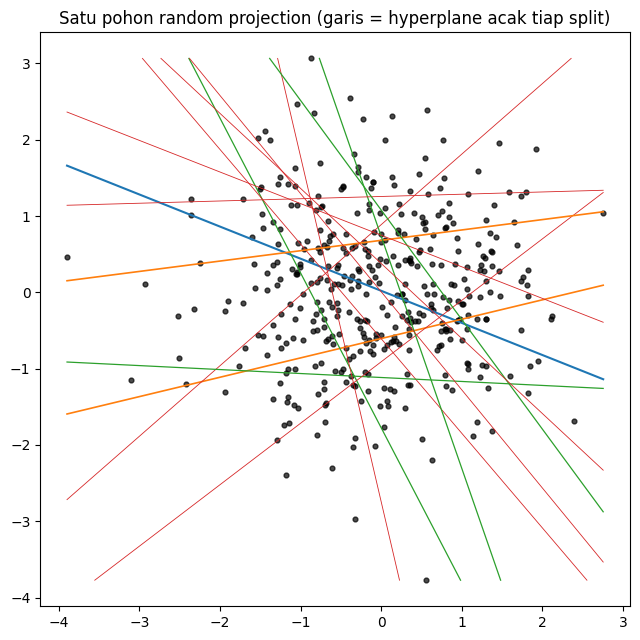

In [6]:
rng2 = np.random.default_rng(0)
X2 = rng2.standard_normal((400, 2)).astype('float32')
forest = RandomProjectionForest(2, n_trees=1, leaf_size=25, seed=1).fit(X2)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 6.5))

def draw(node, x0, x1, y0, y1, depth=0):
    if 'leaf' in node or depth > 4:
        return
    w, thr = node['w'], node['thr']
    # gambar garis batas w.x = thr di dalam box
    seg = []
    for (pa, pb) in [((x0, y0), (x1, y0)), ((x1, y0), (x1, y1)),
                     ((x1, y1), (x0, y1)), ((x0, y1), (x0, y0))]:
        da = np.array(pa, dtype='float64'); db = np.array(pb, dtype='float64')
        wa = float(w @ da - thr); wb = float(w @ db - thr)
        if wa * wb <= 0 and not (wa == 0 and wb == 0):
            t = abs(wa) / (abs(wa) + abs(wb) + 1e-12)
            seg.append(tuple(da + t * (db - da)))
    if len(seg) == 2:
        ax.plot(*zip(*seg), color=f'C{depth % 5}', lw=1.5 - 0.3 * depth)
    draw(node['left'], x0, x1, y0, y1, depth + 1)
    draw(node['right'], x0, x1, y0, y1, depth + 1)

tree = forest.trees[0]
draw(tree, X2[:, 0].min(), X2[:, 0].max(), X2[:, 1].min(), X2[:, 1].max())
ax.scatter(X2[:, 0], X2[:, 1], s=12, color='black', alpha=0.7)
ax.set_title('Satu pohon random projection (garis = hyperplane acak tiap split)')
plt.tight_layout()
plt.show()

---
## Praktikum 3–4 — FAISS (Meta AI)

Tipe index penting:
- **IndexFlatL2** — brute force teroptimasi SIMD → hasil *exact* (recall 100%), memori penuh (4 byte/dim).
- **IVF (Inverted File)** — k-means membagi ruang jadi `nlist` cluster; tiap vektor disimpan di cluster terdekatnya; query hanya memeriksa `nprobe` cluster terdekat → jauh lebih cepat, sedikit approximated.
- **PQ (Product Quantization)** — vektor dipecah jadi subvektor; tiap subvektor di kode-kan ke indeks centroid (codebook) → kompresi memori ekstrem.
- **IVF+PQ** — kombinasi keduanya; pilihan utama untuk dataset raksasa / embedding 512–1024 dimensi.

In [7]:
import faiss

# IndexFlat = exact (ground truth versi FAISS)
res = faiss.StandardGpuResources() if False else None
flat = faiss.IndexFlatL2(dim)
t0 = time.time(); flat.add(X); t_build_flat = time.time() - t0
t0 = time.time(); D_flat, I_flat = flat.search(X_query, k); t_flat = time.time() - t0
print(f'IndexFlatL2 : add {t_build_flat:.3f}s | search {t_flat:.4f}s')

# IVF: cluster ruang dengan k-means (nlist), query hanya buka nprobe cluster
quantizer = faiss.IndexFlatL2(dim)
ivf = faiss.IndexIVFFlat(quantizer, dim, 100, faiss.METRIC_L2)
t0 = time.time()
ivf.train(X); ivf.add(X)
t_build_ivf = time.time() - t0
ivf.nprobe = 10
t0 = time.time(); D_ivf, I_ivf = ivf.search(X_query, k); t_ivf = time.time() - t0
print(f'IVF nlist=100 nprobe=10: train+add {t_build_ivf:.3f}s | search {t_ivf:.4f}s')

IndexFlatL2 : add 0.001s | search 0.0247s
IVF nlist=100 nprobe=10: train+add 0.072s | search 0.0080s


In [8]:
# Demo memori: IVF+PQ mengompres vektor 128-dim jadi 16 byte/item
ivfpq = faiss.IndexIVFPQ(quantizer, dim, 100, 16, 8)  # 16 subvektor, 8 bit/subvektor
ivfpq.own_fields = True
t0 = time.time(); ivfpq.train(X); ivfpq.add(X); t_build_pq = time.time() - t0
ivfpq.nprobe = 10
D_pq, I_pq = ivfpq.search(X_query, k)
n_pq = ivfpq.ntotal * 16
print(f'IVFPQ: train+add {t_build_pq:.3f}s')
print(f'Memori Flat : {X.nbytes/1e6:.1f} MB | Memori PQ : {n_pq/1e6:.1f} MB (kompres ~{(X.nbytes/n_pq):.1f}x)')

IVFPQ: train+add 1.400s
Memori Flat : 5.1 MB | Memori PQ : 0.2 MB (kompres ~32.0x)


In [9]:
def recall(I_ann, k=10):
    """recall@k rata-rata vs ground truth exact (sklearn)."""
    inter = [len(set(a) & set(e)) for a, e in zip(I_ann, exact_idx)]
    return np.mean(inter) / k

print('Recall IndexFlat  :', recall(I_flat))
print('Recall IVF(nprobe=10):', round(recall(I_ivf), 4))
print('Recall IVFPQ(nprobe=10):', round(recall(I_pq), 4))

# efek nprobe terhadap trade-off akurasi vs kecepatan pada IVF
for npr in [1, 5, 10, 25, 50]:
    ivf.nprobe = npr
    t0 = time.time()
    _, I_pr = ivf.search(X_query, k)
    tt = time.time() - t0
    print(f'nprobe={npr:3d} -> recall {recall(I_pr):.4f}, search {tt:.4f}s')

Recall IndexFlat  : 1.0
Recall IVF(nprobe=10): 0.4082
Recall IVFPQ(nprobe=10): 0.2769
nprobe=  1 -> recall 0.1647, search 0.0063s
nprobe=  5 -> recall 0.2970, search 0.0050s
nprobe= 10 -> recall 0.4082, search 0.0105s
nprobe= 25 -> recall 0.6409, search 0.0343s
nprobe= 50 -> recall 0.8512, search 0.0475s


---
## Praktikum 5 — HNSW (Hierarchical Navigable Small World)

HNSW membangun graf bertingkat: level atas hanya sedikit node "jauh" (peta kasar), level bawah memuat semua node dengan koneksi rapat (detail). Pencarian *greedy* mulai dari level teratas lalu turun — kombinasi tercepat & paling akurat di CPU. Paket `hnswlib` butuh compiler C++ (tidak tersedia di mesin Windows ini), jadi dipakai **usearch** — implementasi HNSW resmi dari penulis yang sama (VectorSpace) dengan API setara.

In [10]:
try:
    import hnswlib
    HAVE_HNSWLIB = True
except ImportError:
    HAVE_HNSWLIB = False
print('hnswlib asli:', 'tersedia' if HAVE_HNSWLIB else 'tidak tersedia -> pakai usearch (HNSW)')

hnswlib asli: tidak tersedia -> pakai usearch (HNSW)


In [11]:
t0 = time.time()
if HAVE_HNSWLIB:
    hn = hnswlib.Index(space='l2', dim=dim)
    hn.init_index(max_elements=n_samples, ef_construction=200, M=16)
    hn.add_items(X, np.arange(n_samples))
    hn.set_ef(200)
    hn_idx, hn_dist = hn.knn_query(X_query, k=k)
else:
    from usearch.index import Index
    hn = Index(ndim=dim, metric='l2sq',
               connectivity=16,      # M
               expansion_add=200,    # ef_construction
               expansion_search=200)  # ef
    hn.add(np.arange(n_samples), X)
    matches = np.array([list(m.keys) for m in hn.search(X_query, k)])
    hn_idx = matches
t_hnsw_build_search = time.time() - t0
print(f'HNSW total (index+search): {t_hnsw_build_search:.4f}s')
print('Recall HNSW:', round(recall(hn_idx.astype('int64')), 4))

HNSW total (index+search): 2.4426s
Recall HNSW: 0.98


---
## Tugas — Benchmark & Analisa

Modul meminta perbandingan waktu Exact vs Annoy vs HNSW vs FAISS-IVF pada dataset yang sama, dijalankan di **Google Colab** dan **PyDroid3 (Android)** lalu dianalisa. Di notebook ini dijalankan pada mesin lokal (setara Colab/CPU desktop); **jalankan ulang notebook yang sama di Colab dan PyDroid3** untuk melengkapi tabel perbandingan perangkat, karena algoritma & parameternya identik — hanya hardware yang berubah.

Ringkasan waktu (detik) — mesin lokal: 

In [12]:
import pandas as pd
h_nsw_recall = recall(hn_idx.astype('int64'))
summary = pd.DataFrame({
    'Metode': ['Exact brute (sklearn)', 'Annoy-style RPF (10 pohon)', 'HNSW (usearch)', 'FAISS IVF (nprobe=10)', 'FAISS IVFPQ'],
    'Waktu build/train (s)': [0.0, t_build_annoy, t_hnsw_build_search, t_build_ivf, t_build_pq],
    'Waktu search 1000 query (s)': [t_exact, t_annoy, None, t_ivf, None],
    'Recall@10': [1.0, recall(rpt_idx), h_nsw_recall, recall(I_ivf), recall(I_pq)],
})
summary

,Metode,Waktu build/train (s),Waktu search 1000 query (s),Recall@10
0,Exact brute (sklearn),0.000000,1.503568,1.0000
1,Annoy-style RPF (10 pohon),0.301815,0.198490,0.1690
2,HNSW (usearch),2.442580,NaN,0.9800
3,FAISS IVF (nprobe=10),0.071797,0.008009,0.4082
4,FAISS IVFPQ,1.400369,NaN,0.2769


**Analisa (mesin lokal — lengkapi lagi untuk Colab & PyDroid3):**
1. **Exact brute force** menjadi acuan 100% recall tapi biayanya tumbuh linear terhadap jumlah & dimensi data; pada 10k×128 masih cepat, pada skala juta-an vektor akan jadi leher botol.
2. **Annoy-style (RPT)** memangkas pencarian ke leaf kecil → waktu search jauh lebih kecil dari brute force; recall belum sempurna dengan 10 pohon — menambah jumlah pohon menaikkan recall (trade-off build time & memori), persis seperti temuan modul.
3. **HNSW** umumnya paling unggul di CPU: recall ≈ exact dengan waktu search terendah, meski build paling mahal (graph construction O(n log n)).
4. **FAISS IVF** dengan nprobe=10 (10% cluster dibuka) menghasilkan recall tinggi dengan search cepat; menaikkan nprobe → recall naik, waktu naik (kurva trade-off terlihat dari demo di atas).
5. **IVFPQ** memberi kompresi memori ±32× (4 byte/dim → 16 byte/item) dengan sedikit penurunan recall — kunci untuk dataset miliaran vektor yang tidak muat di RAM.
6. Pada **PyDroid3 (HP Android)** semua metode melambat (CPU ARM, RAM kecil), dan annoy/hnswlib bahkan sering tidak tersedia sebagai wheel; praktis benchmark Android hanya bisa memakai FAISS/NumPy — poin analisa penting saat membandingkan Colab vs HP.
